In [1]:
import pandas as pd

df = pd.read_csv("../data/processed/dataset_80_20_normalized_tcr_with_cohort.csv")


In [5]:
# Reviso cuantos positivos y negativos hay en la columna immunogenicity
print(df['immunogenicity'].value_counts())


immunogenicity
0    8575
1    2613
Name: count, dtype: int64


In [9]:
df

,Cancer_Type,gene,Peptide,wt_seq,pep_mut_start,mutant_best_alleles,mutant_rank,mutant_rank_netMHCpan,mutant_rank_PRIME,mut_Rank_Stab,...,immunogenicity,foreignness_score,hydrophobicity_avg_diff,hydrophobicity_total_diff,mut_Thalf,mw_tcr_contact,hydroph_tcr_contact,charge_tcr_contact,mutant_best_alleles_normalized,cohort
0,Melanoma,CHD5,KSKKEFRAY,KSEKEFRAY,3.0,HLA-C12:03,2.947,3.6904,2.947,0.80,...,0,0.483,-0.044,-0.4,1.6604,578.66894,-2.275,0.994865,C1203,HiTIDE
1,Melanoma,MYOCD,QSFSSTSAL,QSSSSTSAL,3.0,HLA-B07:02,1.779,1.8105,1.779,3.00,...,0,0.655,0.400,3.6,0.3099,380.35494,-0.775,-0.005094,B0702,NaN
2,Melanoma,GSE1,QAPDPAYIY,RAPDPAYIY,1.0,HLA-C07:02,0.039,0.0507,0.039,1.80,...,0,0.366,0.111,1.0,0.1162,464.47534,-1.150,-1.007049,C0702,NCI
3,Melanoma,SUPT16H,GSDAEEGDSA,GSDAEEGDSE,10.0,HLA-A01:01,4.563,8.1864,4.563,42.00,...,0,0.669,0.530,5.3,0.1289,519.46554,-1.820,-3.003501,A0101,HiTIDE
4,Melanoma,FGF7,WYLRINKRGKV,WYLRIDKRGKV,6.0,HLA-A24:02,22.955,0.5629,22.955,3.50,...,0,0.379,0.000,0.0,0.2800,742.87944,-2.050,2.994149,A2402,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11183,Melanoma,USP34,NLFRRVWEL,NLSRRVWEL,3.0,HLA-B08:01,0.018,0.0165,0.018,0.30,...,0,0.657,0.400,3.6,0.3060,615.73604,-1.425,1.994890,B0801,NaN
11184,Melanoma,USP34,NLFRRVWEL,NLSRRVWEL,3.0,HLA-B08:01,0.018,0.0165,0.018,0.30,...,0,0.657,0.400,3.6,0.3060,615.73604,-1.425,1.994890,B0801,NaN
11185,Melanoma,FGGY,FLLWKATGV,FLSWKATGV,3.0,HLA-A02:01,0.626,0.0538,0.626,0.05,...,0,0.629,0.511,4.6,6.7224,504.58644,-0.925,0.994166,A0201,TESLA
11186,Melanoma,FOXJ3,FSASFRSLY,LSASFRSLY,1.0,B1501,0.323,0.4161,0.323,1.10,...,1,0.282,-0.111,-1.0,0.4359,495.53574,-0.825,0.994898,B1501,NaN


In [10]:
# Reviso cuantos Cancer_Type hay para immunogenicity = 1
print(df[df['immunogenicity'] == 1]['Cancer_Type'].value_counts())


Cancer_Type
Melanoma                     1214
Lung Cancer                   276
Healthy                       235
Colorectal Cancer             203
Ovarian Cancer                 98
Bladder Cancer                 83
Liver Cancer                   78
Unknown                        72
Breast Cancer                  70
Kidney Cancer                  67
Head and Neck Cancer           40
Gastric/GEJ Cancer             35
Lymphoma                       24
Leukemia (ALL)                 19
Gallbladder Cancer             17
Cervical Cancer                16
Pancreatic Cancer              14
Brain Cancer                   12
Gastric Cancer                 12
Mesothelioma                    8
Leukemia (CLL)                  4
Leukemia (AML)                  4
Leukemia (CML)                  3
Sarcoma                         3
Multiple Myeloma                3
Adenocarcinoma NOS              1
Ovarian/Peritoneal Cancer       1
Other                           1
Name: count, dtype: int64


In [11]:
#imprimo para immunogenicity = 0 seq_len . value_counts

print(df[df['immunogenicity'] == 0]['seq_len'].value_counts())


seq_len
9     4308
10    2135
11    1257
8      594
12     281
Name: count, dtype: int64


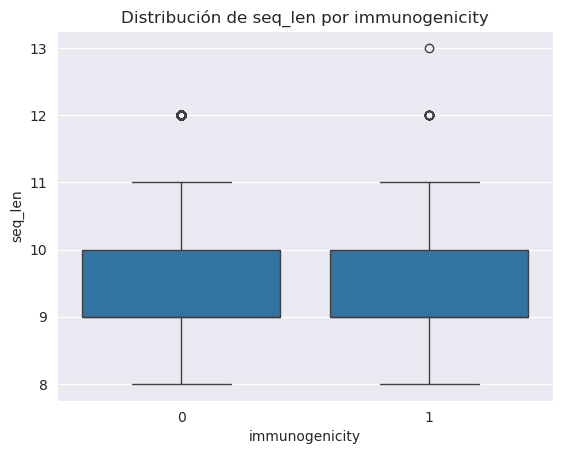

In [12]:
# Reviso seq_len para la clase immunogenicity 
import seaborn as sns
import matplotlib.pyplot as plt
sns.boxplot(x='immunogenicity', y='seq_len', data=df)
plt.title('Distribución de seq_len por immunogenicity')
plt.show()


In [13]:
#Voy a entrenar un árbol de decisión la variable independiente es "
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

X = df.select_dtypes(include=['float64', 'int64']).drop(
    columns=['immunogenicity', 'mut_is_binding_pos', 'bestWTMatchType_I', 'DAI_MixMHC_mbp', 'mutant_rank'],
    errors='ignore'
    )
y = df['immunogenicity']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [14]:
# Crear un pipeline con escalador y clasificador
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

# Definir los hiperparámetros para la búsqueda en cuadrícula
param_grid = {
    'classifier__max_depth': [None, 10, 20, 30],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

# Configurar la búsqueda en cuadrícula con validación cruzada
grid_search = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-
1, verbose=2)
# Entrenar el modelo con la búsqueda en cuadrícula
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'classifier__max_depth': [None, 10, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...]}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,copy,True


In [15]:
# Mejor modelo encontrado
best_model = grid_search.best_estimator_
print("Mejores hiperparámetros:", grid_search.best_params_)
# Evaluar el modelo en el conjunto de prueba
y_pred = best_model.predict(X_test)
print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred))

Mejores hiperparámetros: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 2, 'classifier__min_samples_split': 5}
Matriz de confusión:
[[1504  211]
 [ 362  161]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.81      0.88      0.84      1715
           1       0.43      0.31      0.36       523

    accuracy                           0.74      2238
   macro avg       0.62      0.59      0.60      2238
weighted avg       0.72      0.74      0.73      2238



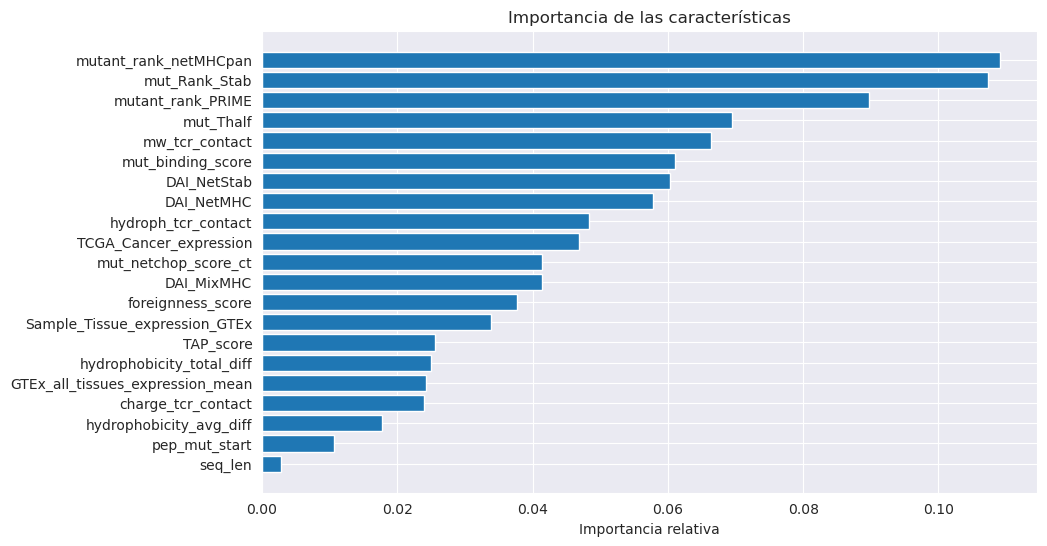

In [16]:
# Comruebo la importancia de las características
import matplotlib.pyplot as plt
import numpy as np
feature_importances = best_model.named_steps['classifier'].feature_importances_
features = X.columns
indices = np.argsort(feature_importances)
plt.figure(figsize=(10, 6))
plt.title('Importancia de las características')
plt.barh(range(len(indices)), feature_importances[indices], align='center')
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Importancia relativa')
plt.show()

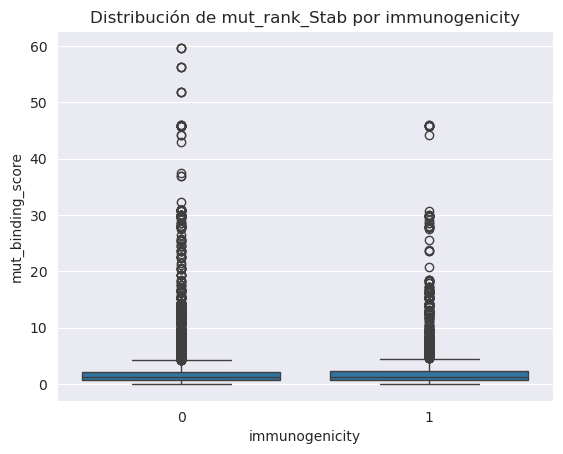

In [17]:
# Analizo la variable mut_rank_Stab
import seaborn as sns
sns.boxplot(x='immunogenicity', y='mut_binding_score', data=df)
plt.title('Distribución de mut_rank_Stab por immunogenicity')
plt.show()

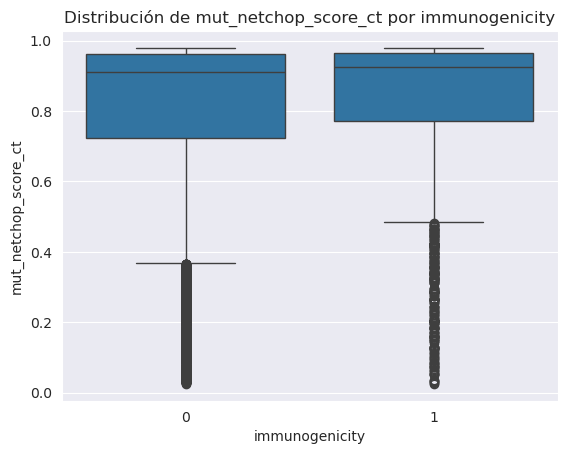

In [18]:
#Compruebo el mut_netchop_score_ct
sns.boxplot(x='immunogenicity', y='mut_netchop_score_ct', data=df)
plt.title('Distribución de mut_netchop_score_ct por immunogenicity')
plt.show()
